# Mixed carbonate-siliciclastic margin: results

The passive margin of the `stratigraphic_record` example (rivers, shelf,
clinoforms, flexure), with two wet catchments feeding two large deltas and
goSPL's carbonate module on the shelf. The runs are described in `README.md`
and in the header of each `input-*.yml`; run `python scripts/make_inputs.py`
and `./run_all.sh` first. The plotting functions are in `scripts/mixed.py`.

In [1]:
import sys
sys.path.insert(0, 'scripts')
import matplotlib.pyplot as plt
import mixed as M

## The forcing

The synthetic sea level of `stratigraphic_record` over its whole 500 kyr: a
fall from +1 m to -38 m (330 kyr), with 5-15 m oscillations on the way
(highstands near 60, 115 and 215 kyr), then a rise to -20 m. The rain is
2 m/yr in two belts (y = 25 and 75 km) and 0.3 m/yr elsewhere: two large
rivers build deltas, and the coast between them (y = 50 km) receives little
river sediment.

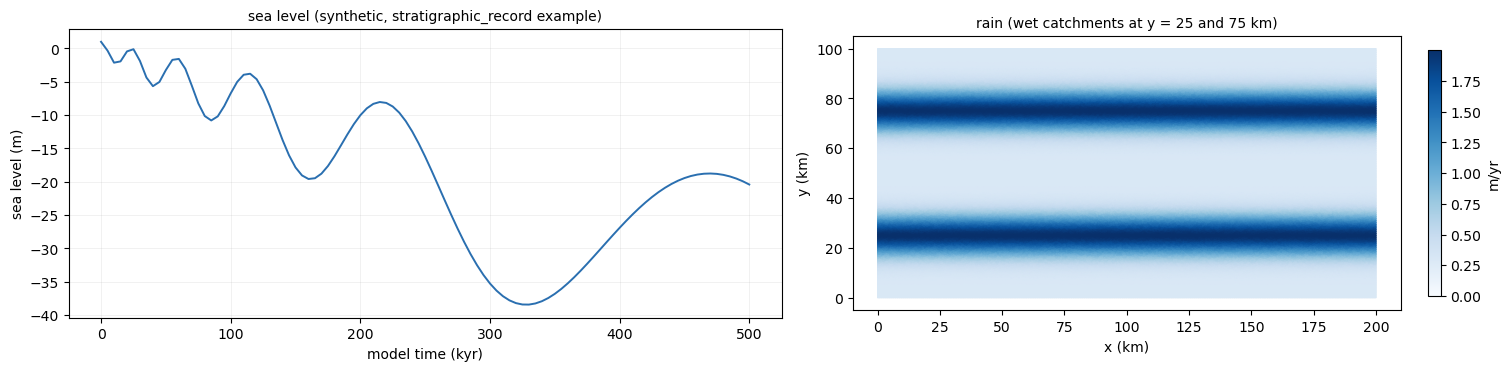

In [2]:
M.forcing();

## The reference mixed margin (`input-mixed.yml`)

The two deltas build out furthest (dashed lines); the coast between them
(solid line) builds less far, and with a larger share of carbonate. The share
of carbonate is highest on the inner shelf (the late, transgressive cover),
lowest on the delta fronts.

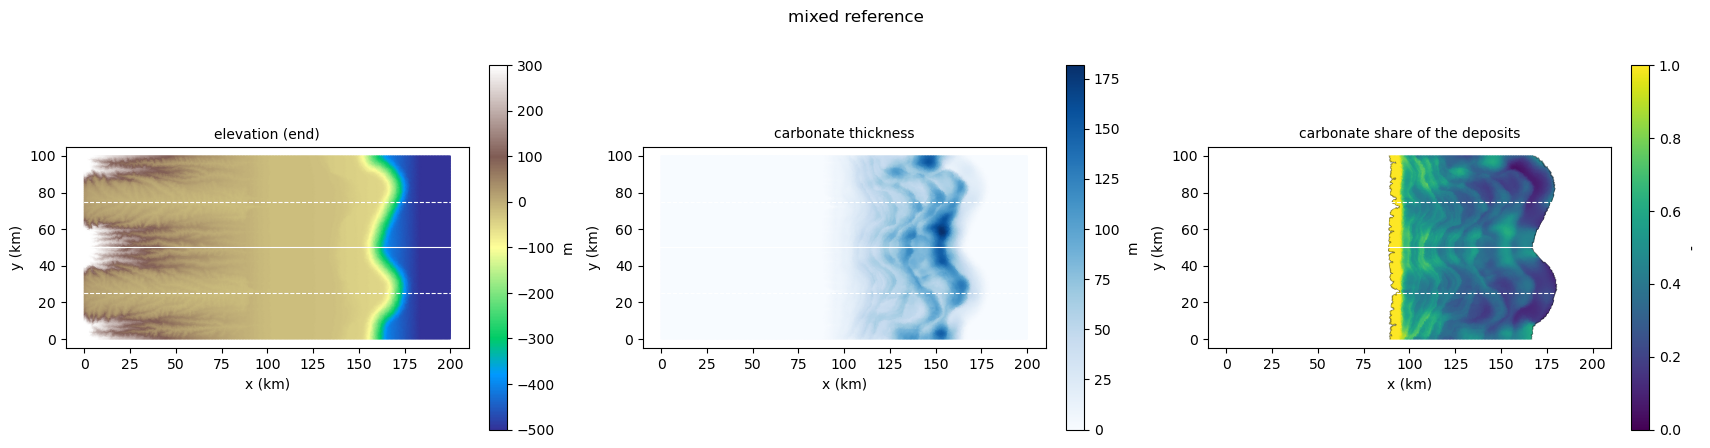

In [3]:
M.maps('sim_mixed', 'mixed reference');

Carbonate production through time, with the shoreline. The factories
follow the sea level: during the slow fall (260 kyr) the shallow belt is
exposed and narrow, and the production almost stops while the rivers build
out; at the lowstand it restarts in patches; during the rise (500 kyr) a wide
belt grows again on the flooded shelf. This alternation of clastic and
carbonate deposition with sea level is the reciprocal sedimentation of mixed
systems.

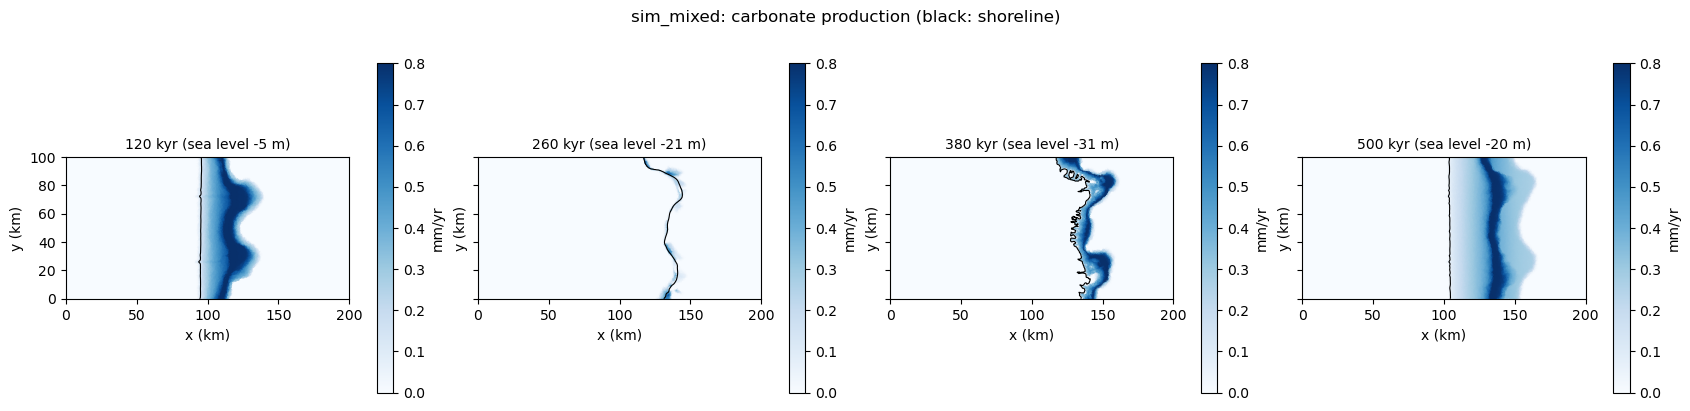

In [4]:
M.production('sim_mixed');

Sections across a delta (y = 25 km) and across the coast between the deltas
(y = 50 km), with the same section through the siliciclastic reference. The
falling stage builds clastic clinoforms (sand yellow, mud grey); carbonate
sand (light blue) and reef framework (pink) cap them and build carbonate
clinoforms of their own, more between the deltas, where the margin builds
13 km further out than without carbonates (deposits thicker than 20 m reach
165 km instead of 152 km).

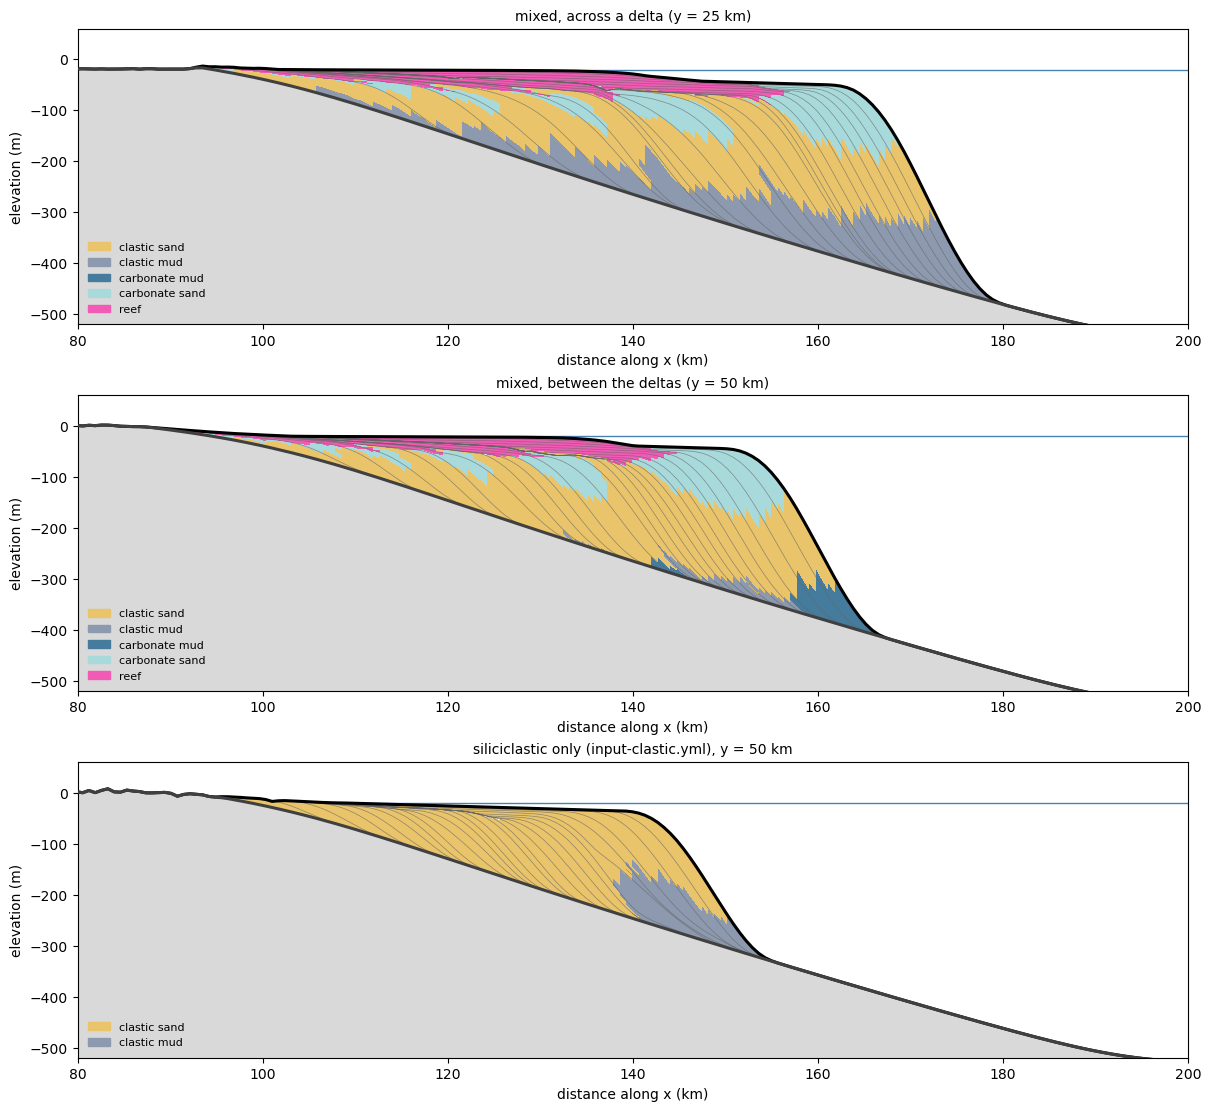

In [5]:
fig, ax = plt.subplots(3, 1, figsize=(12, 11), constrained_layout=True)
M.section('sim_mixed', 25, ax=ax[0], title='mixed, across a delta (y = 25 km)')
M.section('sim_mixed', 50, ax=ax[1], title='mixed, between the deltas (y = 50 km)')
M.section('sim_clastic', 50, ax=ax[2], title='siliciclastic only (input-clastic.yml), y = 50 km');

## The `sedrate` control (`input-nocontrol.yml`)

Without the control, the factories ignore the river sediment and grow on the
delta fronts too: 612 km3 of carbonate against 477 km3 with it. With it,
production stops where more than 0.3 mm/yr of river sediment accumulates.
On this margin most river sediment bypasses the shallow carbonate belt and
builds the clinoforms below it, so the control acts mainly at the river
mouths; the carbonate share falls from 0.37 to 0.33 on the deltas and from
0.52 to 0.45 between them (the river mud also reaches the coast between the
deltas).

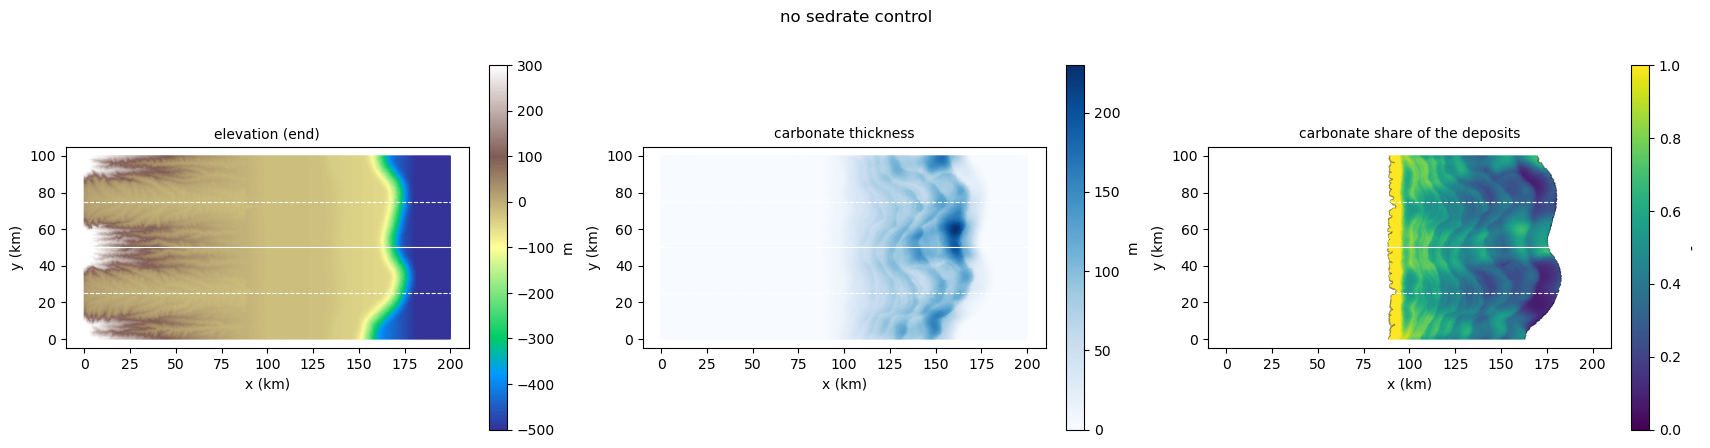

In [6]:
M.maps('sim_nocontrol', 'no sedrate control');

## Waves (`input-wavecontrol.yml`, `input-waves.yml`)

With waves from the open ocean (east) and the reef builders needing wave
energy, the pattern reverses. The delta lobes build steep fronts into deep
water where the reef builders keep the full wave energy; between the deltas
the shelf stays broad and shallow, the waves lose their energy before they
reach the coast and the reef factory works at 20 %. The carbonate builds on
the delta lobes, and the coast between them lags behind (`wavecontrol`). With
coastal erosion as well (`waves`), the waves abrade that starved coast (up to
40 m) and the lag becomes a 30 km embayment; the eroded reef is moved as
carbonate sand and feeds the lobes. Which pattern a real margin follows
depends on its wave climate and its shelf: this is what the wave options let
you test.

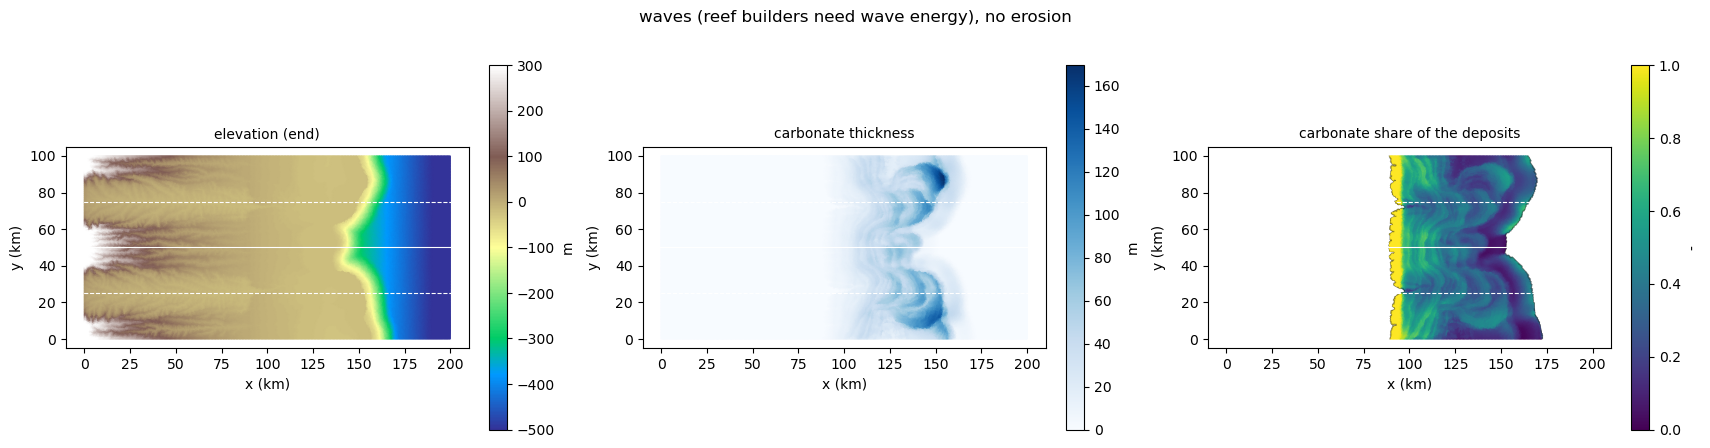

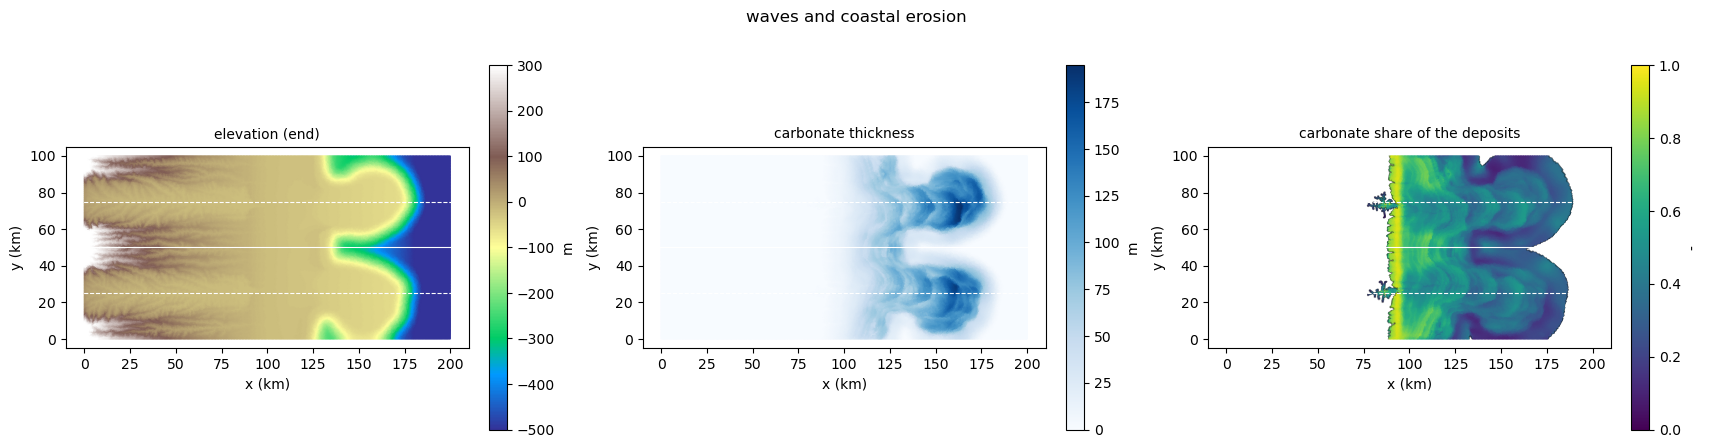

In [7]:
M.maps('sim_wavecontrol', 'waves (reef builders need wave energy), no erosion')
M.maps('sim_waves', 'waves and coastal erosion');

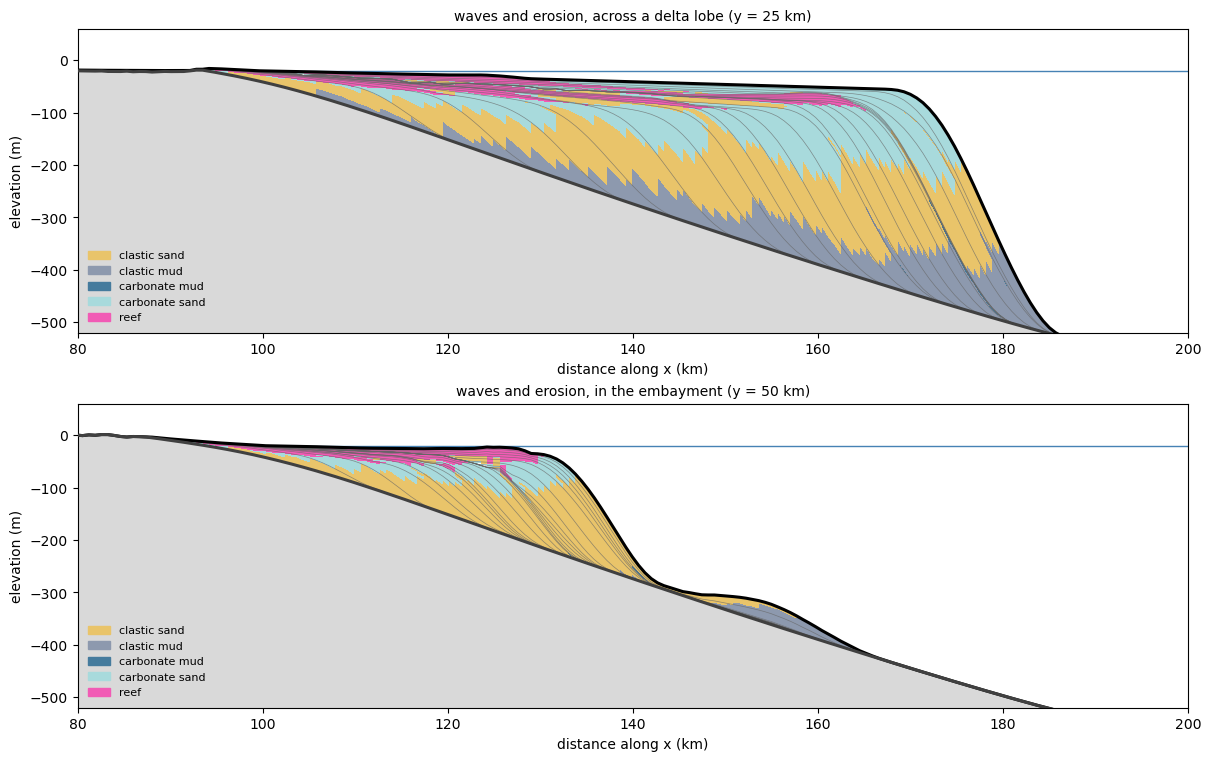

In [8]:
fig, ax = plt.subplots(2, 1, figsize=(12, 7.5), constrained_layout=True)
M.section('sim_waves', 25, ax=ax[0], title='waves and erosion, across a delta lobe (y = 25 km)')
M.section('sim_waves', 50, ax=ax[1], title='waves and erosion, in the embayment (y = 50 km)');

## Gravity currents (`input-gravity.yml`)

30 % of the river load reaching the sea runs down the slope as gravity
currents (the set-up of the `gravity_currents` example). They lay a sheet of
river sand and mud on the basin floor beyond the toe of the slope (23 m on
average beyond 175 km, against 1 m without), and the shelf edge builds out a
little less far, since part of its sediment went to the basin. The carbonates, produced
on the shelf, are not carried by the currents: the basin floor is
siliciclastic.

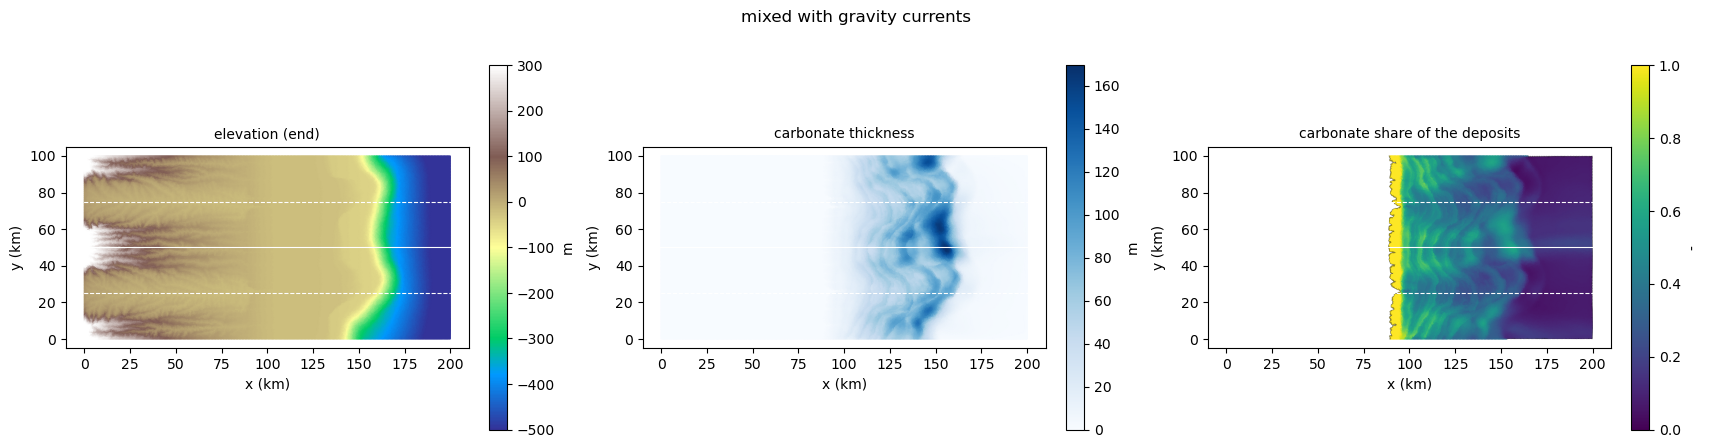

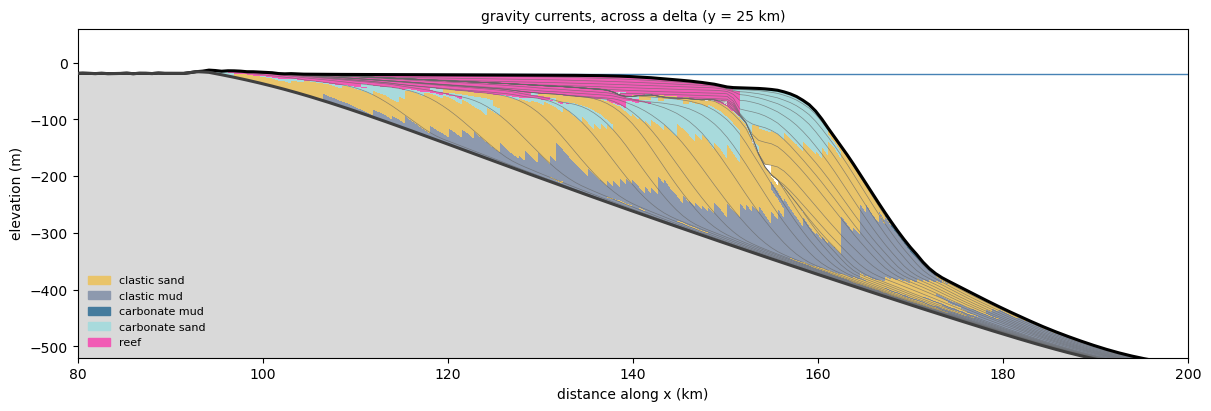

In [9]:
M.maps('sim_gravity', 'mixed with gravity currents')
M.section('sim_gravity', 25, title='gravity currents, across a delta (y = 25 km)');

## Carbonate budgets

Carbonate produced over the run, as reef framework and as loose sediment.
The `sedrate` control removes a fifth of the production; the wave control
removes a further fifth (the reef builders of the sheltered coast); coastal
erosion then raises it again (567 km3 against 382), because it keeps
reopening shallow water where the factories grow.

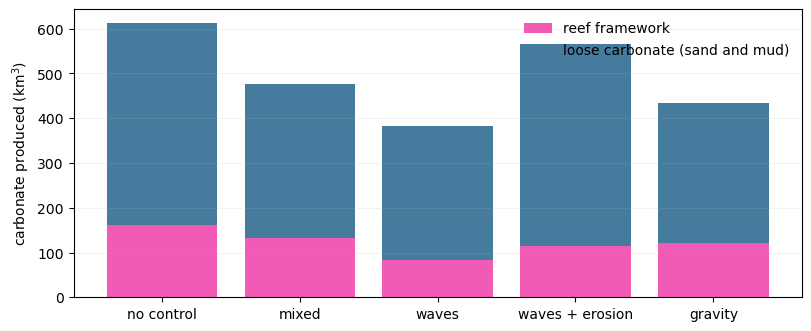

In [10]:
M.budget(['nocontrol', 'mixed', 'wavecontrol', 'waves', 'gravity'],
         ['no control', 'mixed', 'waves', 'waves + erosion', 'gravity']);